<a href="https://colab.research.google.com/github/taheryan/software-testing/blob/main/Software_Testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pynguin pytest pytest-cov pandas matplotlib requests

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires rich<14,>=12.4.4, but you have rich 14.3.4 which is incompatible.


In [2]:
%%writefile app.py


class Store:
    """A small online store with inventory, cart, discounts and orders."""

    FREE_SHIPPING_THRESHOLD = 100.0
    SHIPPING_FEE = 8.0

    def __init__(self):
        self.inventory = {}
        self.cart = {}
        self.discounts = {}
        self.orders = {}
        self.next_order_id = 1

    def add_product(self, sku, price, stock):
        if not isinstance(sku, str) or not sku.strip():
            raise ValueError("SKU must not be empty")
        if not isinstance(price, (int, float)) or isinstance(price, bool):
            raise ValueError("Price must be numeric")
        if price <= 0:
            raise ValueError("Price must be positive")
        if not isinstance(stock, int) or isinstance(stock, bool) or stock < 0:
            raise ValueError("Stock must be a non-negative integer")

        self.inventory[sku] = {
            "price": round(float(price), 2),
            "stock": stock
        }

    def add_discount(self, code, percent, min_total=0, max_uses=1):
        if not isinstance(code, str) or not code.strip():
            raise ValueError("Discount code must not be empty")
        if not isinstance(percent, int) or isinstance(percent, bool):
            raise ValueError("Discount percent must be an integer")
        if not 1 <= percent <= 100:
            raise ValueError("Discount percent must be between 1 and 100")
        if not isinstance(min_total, (int, float)) or isinstance(min_total, bool):
            raise ValueError("Minimum total must be numeric")
        if min_total < 0:
            raise ValueError("Minimum total cannot be negative")
        if not isinstance(max_uses, int) or isinstance(max_uses, bool):
            raise ValueError("Maximum uses must be an integer")
        if max_uses < 1:
            raise ValueError("Maximum uses must be positive")

        self.discounts[code] = {
            "percent": percent,
            "min_total": round(float(min_total), 2),
            "max_uses": max_uses,
            "used": 0
        }

    def add_to_cart(self, sku, quantity):
        if sku not in self.inventory:
            raise KeyError("Product does not exist")
        if not isinstance(quantity, int) or isinstance(quantity, bool):
            raise ValueError("Quantity must be an integer")
        if quantity <= 0:
            raise ValueError("Quantity must be positive")

        current_quantity = self.cart.get(sku, 0)
        available = self.inventory[sku]["stock"]

        if current_quantity + quantity > available:
            raise ValueError("Insufficient stock")

        self.cart[sku] = current_quantity + quantity

    def remove_from_cart(self, sku, quantity):
        if sku not in self.cart:
            raise KeyError("Product is not in the cart")
        if not isinstance(quantity, int) or isinstance(quantity, bool):
            raise ValueError("Quantity must be an integer")
        if quantity <= 0:
            raise ValueError("Quantity must be positive")
        if quantity > self.cart[sku]:
            raise ValueError("Cannot remove more than cart quantity")

        remaining = self.cart[sku] - quantity

        if remaining == 0:
            del self.cart[sku]
        else:
            self.cart[sku] = remaining

    def calculate_subtotal(self):
        total = sum(
            self.inventory[sku]["price"] * quantity
            for sku, quantity in self.cart.items()
        )
        return round(total, 2)

    def calculate_shipping(self, subtotal):
        if subtotal >= self.FREE_SHIPPING_THRESHOLD:
            return 0.0
        return self.SHIPPING_FEE

    def checkout(self, discount_code=None, payment_success=True):
        if not self.cart:
            raise ValueError("Cart is empty")

        subtotal = self.calculate_subtotal()
        discount_amount = 0.0
        discount = None

        if discount_code is not None:
            if discount_code not in self.discounts:
                raise ValueError("Invalid discount code")

            discount = self.discounts[discount_code]

            if discount["used"] >= discount["max_uses"]:
                raise ValueError("Discount usage limit reached")
            if subtotal < discount["min_total"]:
                raise ValueError("Minimum purchase requirement not met")

            discount_amount = round(
                subtotal * discount["percent"] / 100, 2
            )

        shipping = self.calculate_shipping(subtotal)
        total = round(subtotal - discount_amount + shipping, 2)

        if not payment_success:
            raise RuntimeError("Payment failed")

        items = []
        for sku, quantity in self.cart.items():
            product = self.inventory[sku]

            if quantity > product["stock"]:
                raise ValueError("Insufficient stock at checkout")

            items.append({
                "sku": sku,
                "quantity": quantity,
                "unit_price": product["price"]
            })

        for item in items:
            self.inventory[item["sku"]]["stock"] -= item["quantity"]

        if discount is not None:
            discount["used"] += 1

        order_id = self.next_order_id
        self.next_order_id += 1

        self.orders[order_id] = {
            "items": items,
            "subtotal": subtotal,
            "discount": discount_amount,
            "shipping": shipping,
            "total": total,
            "status": "paid"
        }

        self.cart.clear()
        return order_id

    def cancel_order(self, order_id):
        if order_id not in self.orders:
            raise KeyError("Order does not exist")

        order = self.orders[order_id]

        if order["status"] != "paid":
            raise ValueError("Only paid orders can be cancelled")

        for item in order["items"]:
            self.inventory[item["sku"]]["stock"] += item["quantity"]

        order["status"] = "cancelled"
        return True

    def get_order(self, order_id):
        if order_id not in self.orders:
            raise KeyError("Order does not exist")
        return self.orders[order_id]


Writing app.py


In [3]:
%%writefile test_manual.py

import pytest
from app import Store


@pytest.fixture
def store():
    """Create a store with sample products and a discount."""
    s = Store()
    s.add_product("P1", 20.0, 10)
    s.add_product("P2", 50.0, 5)
    s.add_product("P3", 120.0, 3)
    s.add_discount("SAVE10", 10, min_total=50, max_uses=2)
    return s


# --------------------------------------------------
# 1. Product management
# --------------------------------------------------

def test_add_product_success(store):
    store.add_product("P4", 15.0, 8)

    assert store.inventory["P4"]["price"] == 15.0
    assert store.inventory["P4"]["stock"] == 8


def test_add_product_rejects_empty_sku(store):
    with pytest.raises(ValueError):
        store.add_product("", 20.0, 5)


def test_add_product_rejects_non_positive_price(store):
    with pytest.raises(ValueError):
        store.add_product("P4", 0, 5)


def test_add_product_rejects_negative_stock(store):
    with pytest.raises(ValueError):
        store.add_product("P4", 20.0, -1)


# --------------------------------------------------
# 2. Shopping cart
# --------------------------------------------------

def test_add_to_cart_success(store):
    store.add_to_cart("P1", 2)

    assert store.cart == {"P1": 2}


def test_adding_same_product_increases_quantity(store):
    store.add_to_cart("P1", 2)
    store.add_to_cart("P1", 3)

    assert store.cart["P1"] == 5


def test_add_to_cart_rejects_unknown_product(store):
    with pytest.raises(KeyError):
        store.add_to_cart("UNKNOWN", 1)


def test_add_to_cart_rejects_zero_quantity(store):
    with pytest.raises(ValueError):
        store.add_to_cart("P1", 0)


def test_add_to_cart_rejects_insufficient_stock(store):
    with pytest.raises(ValueError):
        store.add_to_cart("P1", 11)


def test_remove_from_cart_success(store):
    store.add_to_cart("P1", 3)
    store.remove_from_cart("P1", 1)

    assert store.cart["P1"] == 2


def test_removing_all_quantity_removes_product_from_cart(store):
    store.add_to_cart("P1", 2)
    store.remove_from_cart("P1", 2)

    assert "P1" not in store.cart


def test_remove_more_than_cart_quantity_is_rejected(store):
    store.add_to_cart("P1", 2)

    with pytest.raises(ValueError):
        store.remove_from_cart("P1", 3)


# --------------------------------------------------
# 3. Price and shipping calculations
# --------------------------------------------------

def test_calculate_subtotal_for_multiple_products(store):
    store.add_to_cart("P1", 2)
    store.add_to_cart("P2", 1)

    assert store.calculate_subtotal() == 90.0


def test_shipping_is_free_at_threshold(store):
    assert store.calculate_shipping(100.0) == 0.0


def test_shipping_is_charged_below_threshold(store):
    assert store.calculate_shipping(99.99) == 8.0


# --------------------------------------------------
# 4. Checkout and discounts
# --------------------------------------------------

def test_checkout_without_discount(store):
    store.add_to_cart("P1", 2)
    order_id = store.checkout()

    order = store.get_order(order_id)

    assert order["subtotal"] == 40.0
    assert order["shipping"] == 8.0
    assert order["total"] == 48.0
    assert order["status"] == "paid"


def test_checkout_applies_discount_correctly(store):
    store.add_to_cart("P2", 2)
    order_id = store.checkout("SAVE10")

    order = store.get_order(order_id)

    assert order["subtotal"] == 100.0
    assert order["discount"] == 10.0
    assert order["shipping"] == 0.0
    assert order["total"] == 90.0


def test_checkout_rejects_empty_cart(store):
    with pytest.raises(ValueError):
        store.checkout()


def test_checkout_rejects_invalid_discount_code(store):
    store.add_to_cart("P2", 2)

    with pytest.raises(ValueError):
        store.checkout("INVALID")


def test_checkout_rejects_discount_below_minimum(store):
    store.add_to_cart("P1", 2)

    with pytest.raises(ValueError):
        store.checkout("SAVE10")


def test_failed_payment_does_not_change_inventory(store):
    store.add_to_cart("P1", 2)
    initial_stock = store.inventory["P1"]["stock"]

    with pytest.raises(RuntimeError):
        store.checkout(payment_success=False)

    assert store.inventory["P1"]["stock"] == initial_stock
    assert store.cart == {"P1": 2}
    assert store.orders == {}


def test_checkout_reduces_inventory(store):
    store.add_to_cart("P1", 3)
    store.checkout()

    assert store.inventory["P1"]["stock"] == 7


def test_discount_usage_limit_is_enforced(store):
    store.add_to_cart("P2", 1)
    store.checkout("SAVE10")

    store.add_to_cart("P2", 1)
    store.checkout("SAVE10")

    store.add_to_cart("P2", 1)

    with pytest.raises(ValueError):
        store.checkout("SAVE10")


# --------------------------------------------------
# 5. Order cancellation
# --------------------------------------------------

def test_cancel_order_restores_inventory(store):
    store.add_to_cart("P1", 3)
    order_id = store.checkout()

    store.cancel_order(order_id)

    assert store.inventory["P1"]["stock"] == 10
    assert store.get_order(order_id)["status"] == "cancelled"


def test_cannot_cancel_order_twice(store):
    store.add_to_cart("P1", 1)
    order_id = store.checkout()

    store.cancel_order(order_id)

    with pytest.raises(ValueError):
        store.cancel_order(order_id)


def test_cannot_cancel_unknown_order(store):
    with pytest.raises(KeyError):
        store.cancel_order(999)


Writing test_manual.py


In [7]:
%%writefile test_llm.py

import pytest
from app import Store

@pytest.fixture
def store():
    return Store()

# ---------- add_product ----------
def test_add_product_valid(store):
    store.add_product("SKU1", 10.5, 5)
    assert store.inventory["SKU1"]["price"] == 10.5
    assert store.inventory["SKU1"]["stock"] == 5

def test_add_product_rounds_price(store):
    store.add_product("SKU1", 10.556, 5)
    assert store.inventory["SKU1"]["price"] == pytest.approx(10.56)

def test_add_product_invalid_sku(store):
    with pytest.raises(ValueError, match="SKU must not be empty"):
        store.add_product("", 10, 5)
    with pytest.raises(ValueError, match="SKU must not be empty"):
        store.add_product("   ", 10, 5)
    with pytest.raises(ValueError, match="SKU must not be empty"):
        store.add_product(123, 10, 5)

def test_add_product_invalid_price(store):
    with pytest.raises(ValueError, match="Price must be numeric"):
        store.add_product("SKU", "10", 5)
    with pytest.raises(ValueError, match="Price must be numeric"):
        store.add_product("SKU", True, 5)
    with pytest.raises(ValueError, match="Price must be positive"):
        store.add_product("SKU", 0, 5)
    with pytest.raises(ValueError, match="Price must be positive"):
        store.add_product("SKU", -1, 5)

def test_add_product_invalid_stock(store):
    with pytest.raises(ValueError, match="Stock must be a non-negative integer"):
        store.add_product("SKU", 10, 5.0)
    with pytest.raises(ValueError, match="Stock must be a non-negative integer"):
        store.add_product("SKU", 10, True)
    with pytest.raises(ValueError, match="Stock must be a non-negative integer"):
        store.add_product("SKU", 10, -1)

def test_add_product_zero_stock(store):
    store.add_product("SKU", 10, 0)
    assert store.inventory["SKU"]["stock"] == 0

# ---------- add_discount ----------
def test_add_discount_valid(store):
    store.add_discount("DISC10", 10, min_total=50, max_uses=3)
    d = store.discounts["DISC10"]
    assert d["percent"] == 10
    assert d["min_total"] == 50.0
    assert d["max_uses"] == 3
    assert d["used"] == 0

def test_add_discount_invalid_code(store):
    with pytest.raises(ValueError, match="Discount code must not be empty"):
        store.add_discount("", 10)
    with pytest.raises(ValueError, match="Discount code must not be empty"):
        store.add_discount("  ", 10)
    with pytest.raises(ValueError, match="Discount code must not be empty"):
        store.add_discount(123, 10)

def test_add_discount_invalid_percent(store):
    with pytest.raises(ValueError, match="Discount percent must be an integer"):
        store.add_discount("D", 10.0)
    with pytest.raises(ValueError, match="Discount percent must be an integer"):
        store.add_discount("D", True)
    with pytest.raises(ValueError, match="Discount percent must be between 1 and 100"):
        store.add_discount("D", 0)
    with pytest.raises(ValueError, match="Discount percent must be between 1 and 100"):
        store.add_discount("D", 101)

def test_add_discount_invalid_min_total(store):
    with pytest.raises(ValueError, match="Minimum total must be numeric"):
        store.add_discount("D", 10, min_total="50")
    with pytest.raises(ValueError, match="Minimum total must be numeric"):
        store.add_discount("D", 10, min_total=True)
    with pytest.raises(ValueError, match="Minimum total cannot be negative"):
        store.add_discount("D", 10, min_total=-1)

def test_add_discount_invalid_max_uses(store):
    with pytest.raises(ValueError, match="Maximum uses must be an integer"):
        store.add_discount("D", 10, max_uses=1.0)
    with pytest.raises(ValueError, match="Maximum uses must be an integer"):
        store.add_discount("D", 10, max_uses=True)
    with pytest.raises(ValueError, match="Maximum uses must be positive"):
        store.add_discount("D", 10, max_uses=0)

# ---------- add_to_cart ----------
def test_add_to_cart_valid(store):
    store.add_product("SKU1", 10, 5)
    store.add_to_cart("SKU1", 2)
    assert store.cart["SKU1"] == 2
    store.add_to_cart("SKU1", 3)
    assert store.cart["SKU1"] == 5

def test_add_to_cart_nonexistent_sku(store):
    with pytest.raises(KeyError, match="Product does not exist"):
        store.add_to_cart("NOPE", 1)

def test_add_to_cart_invalid_quantity(store):
    store.add_product("SKU1", 10, 5)
    with pytest.raises(ValueError, match="Quantity must be an integer"):
        store.add_to_cart("SKU1", 1.0)
    with pytest.raises(ValueError, match="Quantity must be an integer"):
        store.add_to_cart("SKU1", True)
    with pytest.raises(ValueError, match="Quantity must be positive"):
        store.add_to_cart("SKU1", 0)
    with pytest.raises(ValueError, match="Quantity must be positive"):
        store.add_to_cart("SKU1", -1)

def test_add_to_cart_insufficient_stock(store):
    store.add_product("SKU1", 10, 2)
    with pytest.raises(ValueError, match="Insufficient stock"):
        store.add_to_cart("SKU1", 3)
    store.add_to_cart("SKU1", 2)
    with pytest.raises(ValueError, match="Insufficient stock"):
        store.add_to_cart("SKU1", 1)

# ---------- remove_from_cart ----------
def test_remove_from_cart_valid(store):
    store.add_product("SKU1", 10, 5)
    store.add_to_cart("SKU1", 3)
    store.remove_from_cart("SKU1", 1)
    assert store.cart["SKU1"] == 2
    store.remove_from_cart("SKU1", 2)
    assert "SKU1" not in store.cart

def test_remove_from_cart_not_in_cart(store):
    with pytest.raises(KeyError, match="Product is not in the cart"):
        store.remove_from_cart("SKU1", 1)

def test_remove_from_cart_invalid_quantity(store):
    store.add_product("SKU1", 10, 5)
    store.add_to_cart("SKU1", 3)
    with pytest.raises(ValueError, match="Quantity must be an integer"):
        store.remove_from_cart("SKU1", 1.0)
    with pytest.raises(ValueError, match="Quantity must be an integer"):
        store.remove_from_cart("SKU1", True)
    with pytest.raises(ValueError, match="Quantity must be positive"):
        store.remove_from_cart("SKU1", 0)
    with pytest.raises(ValueError, match="Quantity must be positive"):
        store.remove_from_cart("SKU1", -1)

def test_remove_from_cart_more_than_cart(store):
    store.add_product("SKU1", 10, 5)
    store.add_to_cart("SKU1", 3)
    with pytest.raises(ValueError, match="Cannot remove more than cart quantity"):
        store.remove_from_cart("SKU1", 4)

# ---------- calculate_subtotal ----------
def test_calculate_subtotal_empty(store):
    assert store.calculate_subtotal() == 0.0

def test_calculate_subtotal(store):
    store.add_product("A", 10.5, 10)
    store.add_product("B", 20.25, 10)
    store.add_to_cart("A", 2)
    store.add_to_cart("B", 1)
    assert store.calculate_subtotal() == pytest.approx(41.25)

def test_calculate_subtotal_rounding(store):
    store.add_product("A", 10.333, 10)
    store.add_to_cart("A", 3)
    assert store.calculate_subtotal() == pytest.approx(30.99)

# ---------- calculate_shipping ----------
def test_calculate_shipping_below_threshold(store):
    assert store.calculate_shipping(99.99) == 8.0

def test_calculate_shipping_at_threshold(store):
    assert store.calculate_shipping(100.0) == 0.0

def test_calculate_shipping_above_threshold(store):
    assert store.calculate_shipping(100.01) == 0.0

# ---------- checkout ----------
def test_checkout_empty_cart(store):
    with pytest.raises(ValueError, match="Cart is empty"):
        store.checkout()

def test_checkout_success(store):
    store.add_product("A", 10.0, 5)
    store.add_to_cart("A", 2)
    order_id = store.checkout()
    assert order_id == 1
    order = store.orders[1]
    assert order["subtotal"] == 20.0
    assert order["discount"] == 0.0
    assert order["shipping"] == 8.0
    assert order["total"] == 28.0
    assert order["status"] == "paid"
    assert order["items"] == [{"sku": "A", "quantity": 2, "unit_price": 10.0}]
    assert store.cart == {}
    assert store.inventory["A"]["stock"] == 3
    assert store.next_order_id == 2

def test_checkout_multiple_items(store):
    store.add_product("A", 10.0, 5)
    store.add_product("B", 20.0, 5)
    store.add_to_cart("A", 2)
    store.add_to_cart("B", 1)
    order_id = store.checkout()
    order = store.orders[order_id]
    assert order["subtotal"] == 40.0
    assert order["shipping"] == 8.0
    assert order["total"] == 48.0
    assert len(order["items"]) == 2
    assert store.inventory["A"]["stock"] == 3
    assert store.inventory["B"]["stock"] == 4

def test_checkout_free_shipping(store):
    store.add_product("A", 50.0, 5)
    store.add_to_cart("A", 2)
    order_id = store.checkout()
    order = store.orders[order_id]
    assert order["subtotal"] == 100.0
    assert order["shipping"] == 0.0
    assert order["total"] == 100.0

def test_checkout_with_discount(store):
    store.add_product("A", 50.0, 5)
    store.add_discount("D10", 10, min_total=50, max_uses=2)
    store.add_to_cart("A", 2)
    order_id = store.checkout("D10")
    order = store.orders[order_id]
    assert order["subtotal"] == 100.0
    assert order["discount"] == 10.0
    assert order["shipping"] == 0.0
    assert order["total"] == 90.0
    assert store.discounts["D10"]["used"] == 1

def test_checkout_invalid_discount_code(store):
    store.add_product("A", 10.0, 5)
    store.add_to_cart("A", 1)
    with pytest.raises(ValueError, match="Invalid discount code"):
        store.checkout("NOPE")

def test_checkout_discount_usage_limit(store):
    store.add_product("A", 10.0, 5)
    store.add_discount("D", 10, max_uses=1)
    store.add_to_cart("A", 1)
    store.checkout("D")
    store.add_to_cart("A", 1)
    with pytest.raises(ValueError, match="Discount usage limit reached"):
        store.checkout("D")

def test_checkout_discount_min_total_not_met(store):
    store.add_product("A", 10.0, 5)
    store.add_discount("D", 10, min_total=50)
    store.add_to_cart("A", 1)
    with pytest.raises(ValueError, match="Minimum purchase requirement not met"):
        store.checkout("D")

def test_checkout_payment_failure(store):
    store.add_product("A", 10.0, 5)
    store.add_to_cart("A", 1)
    with pytest.raises(RuntimeError, match="Payment failed"):
        store.checkout(payment_success=False)
    assert store.cart == {"A": 1}
    assert store.inventory["A"]["stock"] == 5
    assert store.orders == {}
    assert store.next_order_id == 1

def test_checkout_insufficient_stock_at_checkout(store):
    store.add_product("A", 10.0, 2)
    store.add_to_cart("A", 2)
    store.inventory["A"]["stock"] = 1
    with pytest.raises(ValueError, match="Insufficient stock at checkout"):
        store.checkout()

# ---------- cancel_order ----------
def test_cancel_order_success(store):
    store.add_product("A", 10.0, 5)
    store.add_to_cart("A", 2)
    order_id = store.checkout()
    assert store.inventory["A"]["stock"] == 3
    result = store.cancel_order(order_id)
    assert result is True
    assert store.orders[order_id]["status"] == "cancelled"
    assert store.inventory["A"]["stock"] == 5

def test_cancel_order_not_exist(store):
    with pytest.raises(KeyError, match="Order does not exist"):
        store.cancel_order(999)

def test_cancel_order_already_cancelled(store):
    store.add_product("A", 10.0, 5)
    store.add_to_cart("A", 1)
    order_id = store.checkout()
    store.cancel_order(order_id)
    with pytest.raises(ValueError, match="Only paid orders can be cancelled"):
        store.cancel_order(order_id)

# ---------- get_order ----------
def test_get_order_exists(store):
    store.add_product("A", 10.0, 5)
    store.add_to_cart("A", 1)
    order_id = store.checkout()
    order = store.get_order(order_id)
    assert order == store.orders[order_id]

def test_get_order_not_exist(store):
    with pytest.raises(KeyError, match="Order does not exist"):
        store.get_order(999)

Overwriting test_llm.py


Required packages are ready.

Generating tests with Pynguin...
Command: /usr/bin/python3 -m pynguin --project-path /content --module-name app --output-path /content/pynguin_tests --maximum-search-time 60
Pynguin wall-clock time: 91.61 seconds

Generated Pynguin test files:
 - /content/pynguin_tests/test_app.py

BASELINE TEST EXECUTION

Running Manual tests...
Tests: 26 | Passed: 26 | Failed: 0 | Errors: 0 | Branch coverage: 80.0%

Running LLM tests...
Tests: 40 | Passed: 40 | Failed: 0 | Errors: 0 | Branch coverage: 100.0%

Running Pynguin tests...
Tests: 20 | Passed: 19 | Failed: 0 | Errors: 0 | Branch coverage: 30.0%

Valid source mutations prepared: 10

Manual: killed=10, survived=0, invalid=0, mutation score=100.0%

LLM: killed=10, survived=0, invalid=0, mutation score=100.0%

Pynguin: killed=2, survived=8, invalid=0, mutation score=20.0%

FINAL COMPARISON


,method,tests_reported,passed,failed,errors,branch_coverage_pct,line_coverage_pct,mutation_score_pct,mutants_killed,mutants_survived,mutants_invalid,generation_time_sec,test_execution_time_sec,baseline_passed_all
0,Manual,26,26,0,0,80.0,87.83,100.0,10,0,0,NaN,2.3988,True
1,LLM,40,40,0,0,100.0,100.00,100.0,10,0,0,NaN,2.5718,True
2,Pynguin,20,19,0,0,30.0,42.61,20.0,2,8,0,91.605483,2.1195,True


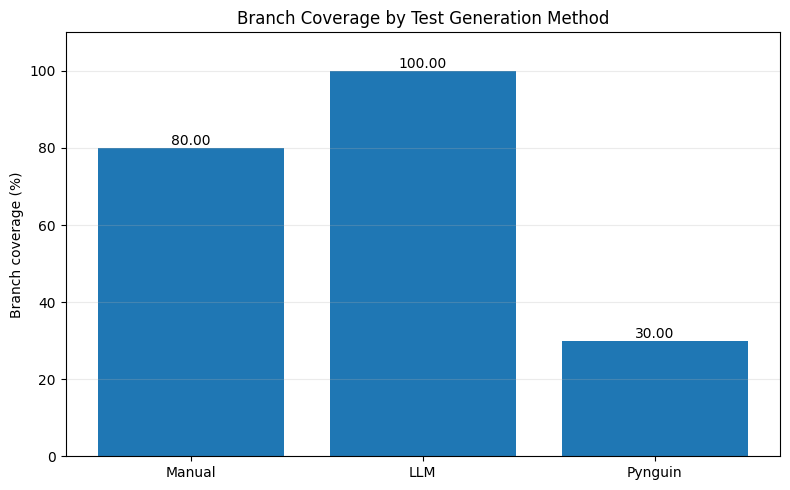

Saved: /content/experiment_results/branch_coverage.png


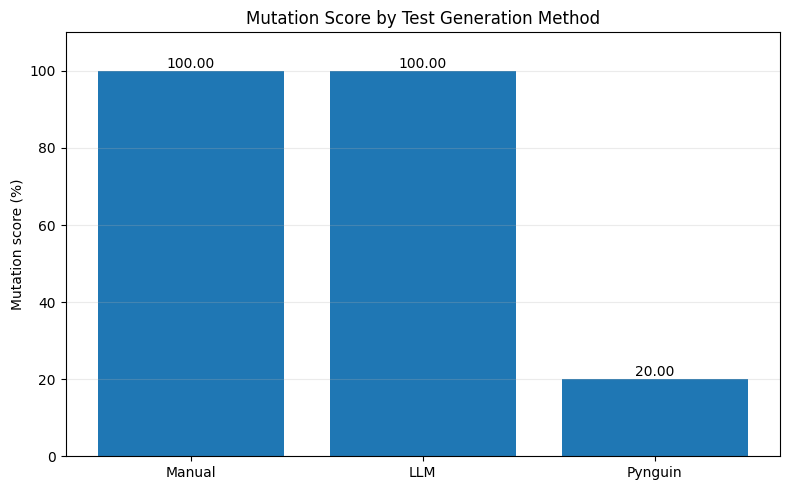

Saved: /content/experiment_results/mutation_score.png


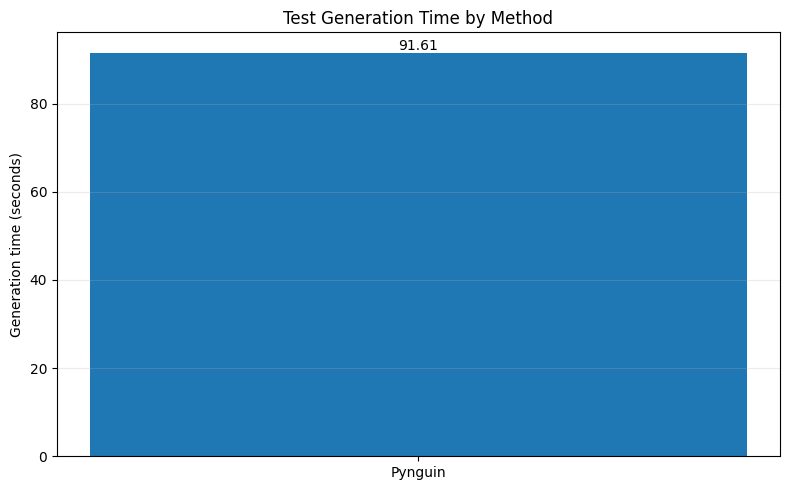

Saved: /content/experiment_results/generation_time.png


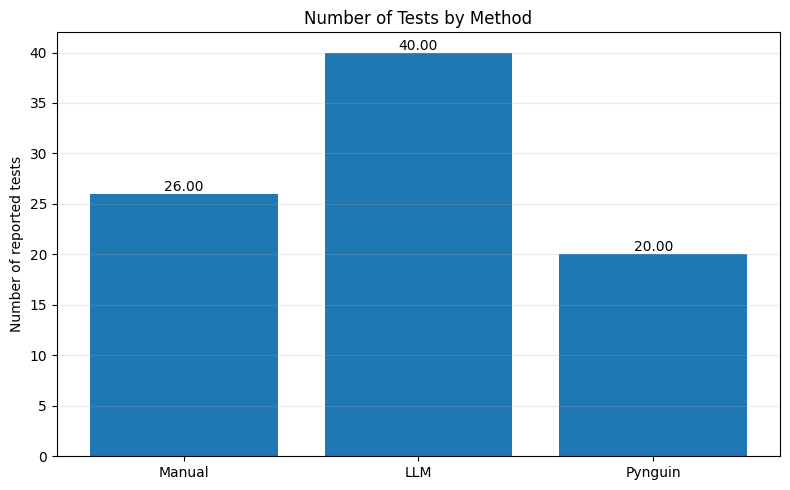

Saved: /content/experiment_results/test_count.png

EXPERIMENT SUMMARY

Method: Manual
  Tests reported: 26
  Passed: 26
  Branch coverage: 80.0%
  Mutation score: 100.0%
  Generation time: nan sec

Method: LLM
  Tests reported: 40
  Passed: 40
  Branch coverage: 100.0%
  Mutation score: 100.0%
  Generation time: nan sec

Method: Pynguin
  Tests reported: 20
  Passed: 19
  Branch coverage: 30.0%
  Mutation score: 20.0%
  Generation time: 91.60548290299994 sec

Results directory: /content/experiment_results
Main CSV: /content/experiment_results/comparison_results.csv
Mutation CSV: /content/experiment_results/mutation_results.csv
Charts:
 - /content/experiment_results/mutation_score.png
 - /content/experiment_results/branch_coverage.png
 - /content/experiment_results/generation_time.png
 - /content/experiment_results/test_count.png


In [8]:

# ============================================================
# EXPERIMENT: Manual vs LLM vs Pynguin
# Platform: Google Colab
# Target module: app.py
# Main metrics: Branch Coverage, Mutation Score, Generation Time
# ============================================================

import os
import sys
import re
import json
import time
import shutil
import subprocess
import tempfile
import math
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

import os
os.environ["PYNGUIN_DANGER_AWARE"] = "1"

import pathlib
pathlib.Path("pynguin_tests").mkdir(exist_ok=True)

BASE_DIR = Path("/content")
APP_FILE = BASE_DIR / "app.py"
MANUAL_FILE = BASE_DIR / "test_manual.py"
LLM_FILE = BASE_DIR / "test_llm.py"

PYNGUIN_DIR = BASE_DIR / "pynguin_tests"
RESULTS_DIR = BASE_DIR / "experiment_results"

PYNGUIN_BUDGET_SECONDS = 60
PYTHON = sys.executable

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

for required_file in [APP_FILE, MANUAL_FILE, LLM_FILE]:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required file not found: {required_file}\n"
            "Upload app.py, test_manual.py and test_llm.py to /content."
        )

# Enter the real time spent writing each suite, in seconds.
# Leave as None if you did not measure it.
MANUAL_GENERATION_TIME_SEC = None
LLM_GENERATION_TIME_SEC = None


# ------------------------------------------------------------
# 2. Install required packages
# ------------------------------------------------------------

def install_package(package):
    result = subprocess.run(
        [PYTHON, "-m", "pip", "install", "-q", package],
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(
            f"Could not install {package}:\n{result.stderr[-3000:]}"
        )

for package in ["pytest", "pytest-cov", "pynguin", "matplotlib", "pandas"]:
    install_package(package)

print("Required packages are ready.")


# ------------------------------------------------------------
# 3. Run Pynguin and measure generation time
# ------------------------------------------------------------

if PYNGUIN_DIR.exists():
    shutil.rmtree(PYNGUIN_DIR)

PYNGUIN_DIR.mkdir(parents=True)

pynguin_command = [
    PYTHON, "-m", "pynguin",
    "--project-path", str(BASE_DIR),
    "--module-name", "app",
    "--output-path", str(PYNGUIN_DIR),
    "--maximum-search-time", str(PYNGUIN_BUDGET_SECONDS),
]

print("\nGenerating tests with Pynguin...")
print("Command:", " ".join(pynguin_command))

pynguin_start = time.perf_counter()
pynguin_process = subprocess.run(
    pynguin_command,
    cwd=str(BASE_DIR),
    capture_output=True,
    text=True
)
pynguin_generation_time = time.perf_counter() - pynguin_start

print(f"Pynguin wall-clock time: {pynguin_generation_time:.2f} seconds")

if pynguin_process.returncode != 0:
    print("\nPynguin stdout (last 3000 characters):")
    print(pynguin_process.stdout[-3000:])
    print("\nPynguin stderr (last 3000 characters):")
    print(pynguin_process.stderr[-3000:])

# Find the generated test module.
pynguin_files = sorted(PYNGUIN_DIR.rglob("test*.py"))

if not pynguin_files:
    raise RuntimeError(
        "Pynguin did not generate a test file. "
        "Check its output above and verify Pynguin compatibility "
        "with the current Colab Python version."
    )

# Keep all generated test files if Pynguin produced more than one.
print("\nGenerated Pynguin test files:")
for path in pynguin_files:
    print(" -", path)


# ------------------------------------------------------------
# 4. Define the three test suites
# ------------------------------------------------------------

suites = {
    "Manual": [MANUAL_FILE],
    "LLM": [LLM_FILE],
    "Pynguin": pynguin_files,
}

generation_times = {
    "Manual": MANUAL_GENERATION_TIME_SEC,
    "LLM": LLM_GENERATION_TIME_SEC,
    "Pynguin": pynguin_generation_time,
}


# ------------------------------------------------------------
# 5. Helpers: isolated test execution and result parsing
# ------------------------------------------------------------

def make_workspace(app_source, test_files):
    """Create an isolated directory containing app.py and test files."""
    temp_dir = Path(tempfile.mkdtemp(prefix="test_experiment_"))

    (temp_dir / "app.py").write_text(
        app_source, encoding="utf-8"
    )

    copied_tests = []

    for index, source_path in enumerate(test_files):
        target_name = source_path.name

        # Avoid collisions if generated files have identical names.
        if (temp_dir / target_name).exists():
            target_name = f"generated_{index}_{target_name}"

        target = temp_dir / target_name
        shutil.copy2(source_path, target)
        copied_tests.append(target)

    return temp_dir, copied_tests


def run_pytest(app_source, test_files, coverage=False):
    """Run tests in isolation and return parsed metrics."""
    temp_dir, copied_tests = make_workspace(app_source, test_files)

    try:
        command = [PYTHON, "-m", "pytest", "-q"]

        coverage_json = temp_dir / "coverage.json"

        if coverage:
            command += [
                "--cov=app",
                "--cov-branch",
                f"--cov-report=json:{coverage_json}",
            ]

        command += [str(path) for path in copied_tests]

        env = os.environ.copy()
        env["PYTHONPATH"] = str(temp_dir)
        env["PYTHONDONTWRITEBYTECODE"] = "1"

        start = time.perf_counter()
        result = subprocess.run(
            command,
            cwd=str(temp_dir),
            env=env,
            capture_output=True,
            text=True,
            timeout=180
        )
        elapsed = time.perf_counter() - start

        output = (result.stdout or "") + "\n" + (result.stderr or "")

        metrics = {
            "tests_reported": 0,
            "passed": 0,
            "failed": 0,
            "errors": 0,
            "skipped": 0,
            "xfailed": 0,
            "exit_code": result.returncode,
            "execution_time_sec": round(elapsed, 4),
            "branch_coverage_pct": None,
            "line_coverage_pct": None,
            "test_output": output[-5000:],
        }

        # Parse pytest summary, including combinations of outcomes.
        summary_patterns = {
            "passed": r"(\d+)\s+passed",
            "failed": r"(\d+)\s+failed",
            "errors": r"(\d+)\s+errors?",
            "skipped": r"(\d+)\s+skipped",
            "xfailed": r"(\d+)\s+xfailed",
        }

        for key, pattern in summary_patterns.items():
            matches = re.findall(pattern, output)
            if matches:
                metrics[key] = int(matches[-1])

        metrics["tests_reported"] = sum(
            metrics[key]
            for key in [
                "passed", "failed", "errors", "skipped", "xfailed"
            ]
        )

        # Read coverage.py JSON summary.
        if coverage and coverage_json.exists():
            coverage_data = json.loads(
                coverage_json.read_text(encoding="utf-8")
            )

            app_summary = coverage_data.get("files", {}).get(
                "app.py", {}
            ).get("summary", {})

            if not app_summary:
                # Try finding the app.py entry by suffix.
                for filename, details in coverage_data.get(
                    "files", {}
                ).items():
                    if filename.endswith("app.py"):
                        app_summary = details.get("summary", {})
                        break

            total_branches = app_summary.get("num_branches", 0)
            missing_branches = app_summary.get("missing_branches", 0)

            if total_branches > 0:
                metrics["branch_coverage_pct"] = round(
                    100 * (total_branches - missing_branches)
                    / total_branches,
                    2
                )

            total_lines = app_summary.get("num_statements", 0)
            missing_lines = app_summary.get("missing_lines", 0)

            if total_lines > 0:
                metrics["line_coverage_pct"] = round(
                    100 * (total_lines - missing_lines) / total_lines,
                    2
                )

        return metrics

    except subprocess.TimeoutExpired:
        return {
            "tests_reported": 0,
            "passed": 0,
            "failed": 0,
            "errors": 1,
            "skipped": 0,
            "xfailed": 0,
            "exit_code": -1,
            "execution_time_sec": None,
            "branch_coverage_pct": None,
            "line_coverage_pct": None,
            "test_output": "Test execution timed out.",
        }

    finally:
        shutil.rmtree(temp_dir, ignore_errors=True)


# ------------------------------------------------------------
# 6. Baseline tests and branch coverage
# ------------------------------------------------------------

original_source = APP_FILE.read_text(encoding="utf-8")
baseline_results = {}

print("\n" + "=" * 65)
print("BASELINE TEST EXECUTION")
print("=" * 65)

for method, test_files in suites.items():
    print(f"\nRunning {method} tests...")

    result = run_pytest(
        original_source,
        test_files,
        coverage=True
    )

    baseline_results[method] = result

    print(
        f"Tests: {result['tests_reported']} | "
        f"Passed: {result['passed']} | "
        f"Failed: {result['failed']} | "
        f"Errors: {result['errors']} | "
        f"Branch coverage: {result['branch_coverage_pct']}%"
    )

    if result["exit_code"] != 0:
        print("Warning: baseline test command returned a non-zero code.")
        print(result["test_output"][-2000:])


# ------------------------------------------------------------
# 7. Controlled mutation testing
# ------------------------------------------------------------
# Each mutation changes one specific behavior in app.py.
# A mutant is killed only if the test run has an ordinary failure
# or error. A suite that fails on the original program is not
# considered valid for mutation-score comparison.

mutations = [
    (
        "shipping_threshold",
        "if subtotal >= self.FREE_SHIPPING_THRESHOLD:",
        "if subtotal > self.FREE_SHIPPING_THRESHOLD:"
    ),
    (
        "shipping_fee",
        "return self.SHIPPING_FEE",
        "return 0.0"
    ),
    (
        "discount_calculation",
        'discount_amount = round(\n'
        '                subtotal * discount["percent"] / 100, 2\n'
        '            )',
        'discount_amount = round(\n'
        '                subtotal * discount["percent"] / 1000, 2\n'
        '            )'
    ),
    (
        "discount_usage",
        'discount["used"] += 1',
        'discount["used"] += 0'
    ),
    (
        "payment_condition",
        "if not payment_success:",
        "if payment_success:"
    ),
    (
        "cart_clearing",
        "        self.cart.clear()\n        return order_id",
        "        pass\n        return order_id"
    ),
    (
        "cancel_status_condition",
        'if order["status"] != "paid":',
        'if order["status"] == "paid":'
    ),
    (
        "cancel_stock_restoration",
        'self.inventory[item["sku"]]["stock"] += item["quantity"]',
        'self.inventory[item["sku"]]["stock"] -= item["quantity"]'
    ),
    (
        "cancelled_status",
        'order["status"] = "cancelled"',
        'order["status"] = "paid"'
    ),
    (
        "cart_quantity_limit",
        "if quantity > self.cart[sku]:",
        "if quantity >= self.cart[sku]:"
    ),
]

# Create only mutants that match the original source exactly.
valid_mutants = []

for mutant_name, old_text, new_text in mutations:
    occurrence_count = original_source.count(old_text)

    if occurrence_count == 1:
        mutated_source = original_source.replace(old_text, new_text, 1)

        if mutated_source != original_source:
            valid_mutants.append((mutant_name, mutated_source))
    else:
        print(
            f"Skipping mutant '{mutant_name}': "
            f"expected exactly 1 match, found {occurrence_count}."
        )

print(f"\nValid source mutations prepared: {len(valid_mutants)}")

mutation_results = []

for method, test_files in suites.items():
    baseline = baseline_results[method]

    # If original tests fail, mutation results are not trustworthy.
    baseline_is_valid = (
        baseline["exit_code"] == 0
        and baseline["failed"] == 0
        and baseline["errors"] == 0
    )

    if not baseline_is_valid:
        print(
            f"\nSkipping mutation score for {method}: "
            "its tests do not all pass on the original program."
        )
        mutation_results.append({
            "method": method,
            "mutants_total": len(valid_mutants),
            "mutants_killed": None,
            "mutants_survived": None,
            "mutation_score_pct": None,
            "mutants_invalid": len(valid_mutants),
        })
        continue

    killed = 0
    survived = 0
    invalid = 0

    for mutant_name, mutated_source in valid_mutants:
        result = run_pytest(
            mutated_source,
            test_files,
            coverage=False
        )

        # Non-zero return can indicate test failures OR collection/
        # import errors. Count as a kill only if an actual test failed.
        # Errors alone do not count as kills.
        if result["failed"] > 0:
            killed += 1
        elif (
            result["exit_code"] == 0
            and result["errors"] == 0
        ):
            survived += 1
        else:
            invalid += 1

    valid_count = killed + survived
    mutation_score = (
        round(100 * killed / valid_count, 2)
        if valid_count > 0 else None
    )

    mutation_results.append({
        "method": method,
        "mutants_total": len(valid_mutants),
        "mutants_killed": killed,
        "mutants_survived": survived,
        "mutation_score_pct": mutation_score,
        "mutants_invalid": invalid,
    })

    print(
        f"\n{method}: killed={killed}, survived={survived}, "
        f"invalid={invalid}, mutation score={mutation_score}%"
    )


# ------------------------------------------------------------
# 8. Build combined results table
# ------------------------------------------------------------

mutation_by_method = {
    row["method"]: row for row in mutation_results
}

rows = []

for method in suites:
    test_result = baseline_results[method]
    mutation_result = mutation_by_method[method]

    rows.append({
        "method": method,
        "tests_reported": test_result["tests_reported"],
        "passed": test_result["passed"],
        "failed": test_result["failed"],
        "errors": test_result["errors"],
        "branch_coverage_pct": test_result["branch_coverage_pct"],
        "line_coverage_pct": test_result["line_coverage_pct"],
        "mutation_score_pct": mutation_result["mutation_score_pct"],
        "mutants_killed": mutation_result["mutants_killed"],
        "mutants_survived": mutation_result["mutants_survived"],
        "mutants_invalid": mutation_result["mutants_invalid"],
        "generation_time_sec": generation_times[method],
        "test_execution_time_sec": test_result["execution_time_sec"],
        "baseline_passed_all": (
            test_result["exit_code"] == 0
            and test_result["failed"] == 0
            and test_result["errors"] == 0
        ),
    })

results_df = pd.DataFrame(rows)

csv_path = RESULTS_DIR / "comparison_results.csv"
results_df.to_csv(csv_path, index=False)

print("\n" + "=" * 65)
print("FINAL COMPARISON")
print("=" * 65)
display(results_df)


# ------------------------------------------------------------
# 9. Save baseline execution logs
# ------------------------------------------------------------

for method, result in baseline_results.items():
    log_path = RESULTS_DIR / f"{method.lower()}_pytest_output.txt"
    log_path.write_text(result["test_output"], encoding="utf-8")

mutation_df = pd.DataFrame(mutation_results)
mutation_df.to_csv(
    RESULTS_DIR / "mutation_results.csv",
    index=False
)


# ------------------------------------------------------------
# 10. Plot comparison charts
# ------------------------------------------------------------

def plot_metric(column, title, ylabel, filename):
    plot_df = results_df[["method", column]].copy()
    plot_df[column] = pd.to_numeric(
        plot_df[column], errors="coerce"
    )

    available = plot_df.dropna(subset=[column])

    plt.figure(figsize=(8, 5))

    if available.empty:
        plt.text(
            0.5, 0.5, "No measured data available",
            ha="center", va="center"
        )
        plt.axis("off")
    else:
        bars = plt.bar(available["method"], available[column])
        plt.title(title)
        plt.ylabel(ylabel)
        plt.grid(axis="y", alpha=0.25)

        for bar, value in zip(bars, available[column]):
            plt.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height(),
                f"{value:.2f}",
                ha="center",
                va="bottom"
            )

        if "coverage" in column or "score" in column:
            plt.ylim(0, 110)

    plt.tight_layout()
    path = RESULTS_DIR / filename
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", path)


plot_metric(
    "branch_coverage_pct",
    "Branch Coverage by Test Generation Method",
    "Branch coverage (%)",
    "branch_coverage.png"
)

plot_metric(
    "mutation_score_pct",
    "Mutation Score by Test Generation Method",
    "Mutation score (%)",
    "mutation_score.png"
)

plot_metric(
    "generation_time_sec",
    "Test Generation Time by Method",
    "Generation time (seconds)",
    "generation_time.png"
)

plot_metric(
    "tests_reported",
    "Number of Tests by Method",
    "Number of reported tests",
    "test_count.png"
)


# ------------------------------------------------------------
# 11. Print a concise report
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT SUMMARY")
print("=" * 65)

for _, row in results_df.iterrows():
    print(f"\nMethod: {row['method']}")
    print(f"  Tests reported: {row['tests_reported']}")
    print(f"  Passed: {row['passed']}")
    print(f"  Branch coverage: {row['branch_coverage_pct']}%")
    print(f"  Mutation score: {row['mutation_score_pct']}%")
    print(f"  Generation time: {row['generation_time_sec']} sec")

print("\nResults directory:", RESULTS_DIR)
print("Main CSV:", csv_path)
print("Mutation CSV:", RESULTS_DIR / "mutation_results.csv")
print("Charts:")
for chart in RESULTS_DIR.glob("*.png"):
    print(" -", chart)
